In [1]:
# try:
#     from ultralytics import YOLO
# except:
#     !pip install -q ultralytics
#     from ultralytics import YOLO

import torch
import yaml
import os
import shutil

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f'Device: {device}')
if device.type == 'cuda':
    print(torch.cuda.get_device_name(0))
    !nvidia-smi


Device: cpu


In [2]:
HOME = os.getcwd()
print(HOME)
project_basepath = f'{HOME}/drive/MyDrive/PROJECT_Fire-Smoke'
dataset_basepath = os.path.join(project_basepath, 'datasets')


/content


# Create Dataset

In [ ]:
# dataset source
!git clone https://github.com/vinchole/zzzccc.git


Cloning into 'zzzccc'...
remote: Enumerating objects: 66, done.
remote: Counting objects: 100% (17/17), done.
remote: Compressing objects: 100% (16/16), done.
remote: Total 66 (delta 1), reused 0 (delta 0), pack-reused 49 (from 1)
Receiving objects: 100% (66/66), 226.91 MiB | 26.26 MiB/s, done.
Resolving deltas: 100% (35/35), done.


In [ ]:
try:
    import patoolib
except:
    !pip install -q patool
    import patoolib

zip_file = f"{HOME}/zzzccc/dataset for papar/dataset1.zip"
output_folder = f"{HOME}/fire-smoke/"
try:
    patoolib.extract_archive(zip_file, outdir=output_folder)
    print("Extraction successful!")
except Exception as e:
    print("Error during extraction:", e)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.4/98.4 kB 2.3 MB/s eta 0:00:00


INFO patool: Extracting /content/zzzccc/dataset for papar/dataset1.zip ...
INFO:patool:Extracting /content/zzzccc/dataset for papar/dataset1.zip ...
INFO patool: ... creating output directory `/content/fire-smoke/'.
INFO:patool:... creating output directory `/content/fire-smoke/'.
INFO patool: running /usr/bin/7z x -aou -o/content/fire-smoke/ -- "/content/zzzccc/dataset for papar/dataset1.zip"
INFO:patool:running /usr/bin/7z x -aou -o/content/fire-smoke/ -- "/content/zzzccc/dataset for papar/dataset1.zip"
INFO patool: ... /content/zzzccc/dataset for papar/dataset1.zip extracted to `/content/fire-smoke/'.
INFO:patool:... /content/zzzccc/dataset for papar/dataset1.zip extracted to `/content/fire-smoke/'.


Extraction successful!


In [ ]:
# # zip the dataset to gdrive
# shutil.make_archive(os.path.join(dataset_basepath, 'fire-smoke'), 'zip', output_folder)


'/content/drive/MyDrive/PROJECT KD/datasets/fire-smoke.zip'

### CLAHE DGC CS

In [ ]:
# !unzip -o "{os.path.join(dataset_basepath, 'fire-smoke.zip')}" -d "{HOME}/fire-smoke"

Streaming output truncated to the last 5000 lines.
  inflating: /content/fire-smoke/valid/labels/WEBSmoke3220_jpg.rf.f04a4bfb85efca082be6091d37c07978.txt  
  inflating: /content/fire-smoke/valid/labels/WEBFire142_jpg.rf.cceea8ef42942fcaa1fad56f0e75f5ac.txt  
  inflating: /content/fire-smoke/valid/labels/MirrorWEBFire1590_jpg.rf.cb51b1ba579b403d2b1543c61debacb0.txt  
  inflating: /content/fire-smoke/valid/labels/WEBSmoke1702_jpg.rf.e7359f70fa1cdae63dc344cae6dd182c.txt  
  inflating: /content/fire-smoke/valid/labels/NoiseWEBFire1708_jpg.rf.0ad08788e19211cfe0b7d91352feda58.txt  
  inflating: /content/fire-smoke/valid/labels/NoiseWEBFire1001_jpg.rf.3da1ab0d16e7ed6f08c27ad4f65ae880.txt  
  inflating: /content/fire-smoke/valid/labels/MirrorWEBSmoke2808_jpg.rf.26c01e7813277b297f8dab0cba59efd5.txt  
  inflating: /content/fire-smoke/valid/labels/NoiseWEBFire285_jpg.rf.51a41425bbbc39472a79d66f5e98c704.txt  
  inflating: /content/fire-smoke/valid/labels/WEBSmoke813_jpg.rf.5f2c514a2a1d0fd80f585d1c

In [ ]:
from PIL import Image
from skimage.color import rgb2hsv, hsv2rgb
import matplotlib.pyplot as plt
import numpy as np
import cv2

# images paths of original dataset
images_paths = {
    'train': os.path.join(HOME, 'fire-smoke/train/images'),
    'valid': os.path.join(HOME, 'fire-smoke/valid/images'),
    'test': os.path.join(HOME, 'fire-smoke/test/images'),
}

def set_he(img):
    yuv = cv2.cvtColor(img, cv2.COLOR_RGB2YUV)
    yuv[:,:,0] = cv2.equalizeHist(yuv[:,:,0])
    result = cv2.cvtColor(yuv, cv2.COLOR_YUV2RGB)
    return result


def set_clahe(img):
    ycrcb = cv2.cvtColor(img, cv2.COLOR_RGB2YCrCb)
    channels = list(cv2.split(ycrcb))

    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
    channels[0] = clahe.apply(channels[0])

    ycrcb = cv2.merge(channels)
    result_bgr = cv2.cvtColor(ycrcb, cv2.COLOR_YCrCb2BGR)
    result = cv2.cvtColor(result_bgr, cv2.COLOR_BGR2RGB)
    return result


def set_cs(img):
    xp = [0, 64, 128, 192, 255]
    fp = [0, 16, 128, 240, 255]
    x = np.arange(256)
    table = np.interp(x, xp, fp).astype('uint8')

    result = cv2.LUT(img, table)
    return result



# dual gamma correction
def compute_clip_limit(
    block: np.ndarray, alpha: float = 40, pi: float = 1.5, R: int = 255
) -> int:
    """This function computes the beta clip limits of each image block

    Args:
        block (np.ndarray): The block of each image
        alpha (float): The alpha variance enhance parameter
        pi (float): The P factor enhanement
        R (int): The color range of the image

    Returns:
        (int): The beta clip limit for the histogram blocks
    """
    avg = block.mean()
    l_max = block.max()
    n = l_max - block.min()
    sigma = block.std()
    m = block.size
    return int(
        (m / (n + 0.001)) * (1 + (pi * l_max / R) + (alpha * sigma / 100.0) / (avg + 0.001))
    )


def clip_and_redistribute_hist(hist: np.ndarray, beta: int) -> np.ndarray:
    """Clips and redistribute the excess values of the histograms among the bins using the block clip value beta

    Args:
        hist (np.ndarray): The block's histogram
        beta (int): The clipping value

    Returns:
        hist (np.ndarray): The redistributed histogram of shape (n_height_blocks, n_width_blocks, bins)
    """
    # compute the exceeded pixels mask
    mask = hist > beta
    exceed_values = hist[mask]
    bin_value = (exceed_values.sum() - exceed_values.size * beta) // hist.size
    hist[mask] = beta
    hist += bin_value
    return hist


def compute_gamma(l_max: int, d_range: int, weighted_cdf: np.ndarray) -> np.ndarray:
    """Computes the Gamma(l) function from paper in a vectorized way across the range of the color space:
    https://www.researcher-app.com/paper/708253

    Args:
        l_max (int): The global max value of the image
        d_range (int): The range of the colors in the image
        weighted_cdf (np.ndarray): The normalized CDF_w()

    Returns:
        (np.ndarray): The gamma vector of size nbins
    """
    return l_max * np.power(np.arange(d_range + 1) / l_max, (1 + weighted_cdf) / 2.0)


def compute_w_en(l_alpha: int, l_max: int, cdf: np.ndarray) -> np.ndarray:
    """Computes the W_en function according to the paper in a vectorized way, for the entire cdf:
        https://www.researcher-app.com/paper/708253I

    Args:
        l_alpha (float): The global l_a variable of the 75th percentile according to the CDF
        l_max (int): the global max intensity value
        cdf (np.ndarray): The normalized cdf

    Returns:
        (np.ndarray): The W_en factors of range of the bin size
    """
    return np.power(l_max / l_alpha if l_alpha != 0 else 0, 1 - (np.log(np.e + cdf) / 8))


def compute_block_coords(
    center_block: int, block_index: int, index: int, n_blocks: int
) -> tuple:
    """This function computes the neighbour block coordinates to interpolate from the histogram. This computes the coords
    of the interpolating blocks from both axis (x, y)

    Args:
        center_block (int): The index of the center block along the pixel coords
        block_index (int): The index of the block in histogram coords
        index (int): The current index of pixel along axis
        n_blocks (int): The amount of blocks along axis

    Returns:
        (int, int): The indexes of the surrounding blocks for each axis
    """
    if index < center_block:
        block_min = block_index - 1
        if block_min < 0:
            block_min = 0
        block_max = block_index
    else:
        block_min = block_index
        block_max = block_index + 1
        if block_max >= n_blocks:
            block_max = block_index
    return block_min, block_max


def compute_mn_factors(coords: tuple, index: int) -> float:
    """Function which computes the interpolation factors of m, n according to the paper. Depending on the axis, it returns
    the proper values
        https://www.researcher-app.com/paper/708253

    Args:
        coords (tuple): The block coordinates (x, y)
        index (int): The pixel index

    Returns:
        (float): The m or n interpolation factors
    """
    if coords[1] - coords[0] == 0:
        return 0
    else:
        return (coords[1] - index) / (coords[1] - coords[0])


def dual_gamma_clahe(
    image: np.ndarray,
    block_size: tuple = (32,32),
    alpha: float = 20,
    pi: float = 1.5,
    delta: float = 50,
    bins: int = 256,
):
    """The dual gamma clahe algorithm taking as inputs the image in numpy format along with the parameters. The algorithm transforms
    the image in HSV if its RGB and applies the equalization on the V channel. If grayscale image applied, then its using it as is.

    Args:
        image (np.ndarray): The image in np format, either grayscale or RGB
        block_size (int, int): The size of the selected block window
        alpha (float): The alpha variance enhance parameter
        pi (float): The P factor enhanement
        delta (float): The threshold value to aply T1 or Gamma depending on the threshold
        bins (int): The number of bins

    Returns:
        (np.ndarray): The enhanced image using dual gamma
    """
    R = bins - 1
    hsv_image = rgb2hsv(image)
    gray_image = hsv_image[:, :, 2]
    gray_image = np.clip(gray_image * 255, 0, 255)

    # Compute global histogram and global values
    glob_l_max = gray_image.max()
    glob_hist = np.histogram(gray_image, bins=bins)[0]
    glob_cdf = np.cumsum(glob_hist)
    glob_cdf = glob_cdf / glob_cdf[-1]
    glob_l_a = np.argwhere(glob_cdf > 0.75)[0]

    pad_height, pad_width = gray_image.shape[:2]
    n_height_blocks = int(pad_height / block_size[0])
    n_width_blocks = int(pad_width / block_size[1])
    hists = np.zeros((n_height_blocks, n_width_blocks, bins))
    beta_thresholds = np.zeros((n_height_blocks, n_width_blocks))
    result = np.zeros_like(gray_image)
    for ii in range(n_height_blocks):
        for jj in range(n_width_blocks):
            block = gray_image[
                ii:ii + block_size[0],
                jj:jj + block_size[1],
            ].astype(np.uint8)

            # Compute the block range and max block value
            max_val_block = block.max()
            r_block = max_val_block - block.min()

            block_equalized = cv2.equalizeHist(block)
            hists[ii, jj] = np.histogram(block_equalized, bins=bins)[0]
            beta_thresholds[ii, jj] = compute_clip_limit(
                block,
                alpha=alpha,
                pi=pi,
                R=R,
            )
            hists[ii, jj] = clip_and_redistribute_hist(
                hists[ii, jj], beta_thresholds[ii, jj]
            )

            pdf_min = hists[ii, jj].min()
            pdf_max = hists[ii, jj].max()

            weighted_hist = pdf_max * (hists[ii, jj] - pdf_min) / (pdf_max - pdf_min)
            weighted_cum_hist = np.cumsum(weighted_hist)
            pdf_sum = weighted_cum_hist[-1]
            weighted_cum_hist /= pdf_sum

            # Equalize histogram here!!!
            hists[ii, jj] = np.cumsum(hists[ii, jj])
            norm_cdf = hists[ii, jj] / hists[ii, jj, -1]

            # Compute Wen T1 and Gamma
            w_en = compute_w_en(l_max=glob_l_max, l_alpha=glob_l_a, cdf=norm_cdf)
            tau_1 = max_val_block * w_en * norm_cdf
            gamma = compute_gamma(
                l_max=glob_l_max, d_range=R, weighted_cdf=weighted_cum_hist
            )

            if r_block > delta:
                hists[ii, jj] = np.maximum(tau_1, gamma)
            else:
                hists[ii, jj] = gamma

    # Bilinear interpolation
    for i in range(pad_height):
        for j in range(pad_width):
            p_i = int(gray_image[i][j])

            # Get current block index
            block_x = i // block_size[0]
            block_y = j // block_size[1]

            # Get the central indexes of the running block
            center_block_x = block_x * block_size[0] + n_height_blocks // 2
            center_block_y = block_y * block_size[1] + n_width_blocks // 2

            # Compute the block coordinates to interpolate from
            block_y_a, block_y_c = compute_block_coords(
                center_block_x, block_x, i, n_height_blocks
            )
            block_x_a, block_x_b = compute_block_coords(
                center_block_y, block_y, j, n_width_blocks
            )

            # Block image coordinates
            y_a = block_y_c * block_size[0] + block_size[0] // 2
            y_c = block_y_a * block_size[0] + block_size[0] // 2
            x_a = block_x_a * block_size[1] + block_size[1] // 2
            x_b = block_x_b * block_size[1] + block_size[1] // 2

            m = compute_mn_factors((y_a, y_c), i)
            n = compute_mn_factors((x_a, x_b), j)

            Ta = hists[block_y_c, block_x_a, p_i]
            Tb = hists[block_y_c, block_x_b, p_i]
            Tc = hists[block_y_a, block_x_a, p_i]
            Td = hists[block_y_a, block_x_b, p_i]

            result[i, j] = int(
                m * (n * Ta + (1 - n) * Tb) + (1 - m) * (n * Tc + (1 - n) * Td)
            )


    result = np.clip(result / 255.0, 0, 1)
    hsv_image[:, :, 2] = result
    return (255 * hsv2rgb(hsv_image)).astype(np.uint8)


Set: train -- /content/fire-smoke/train/images

Original Image: /content/fire-smoke/train/images/MirrorWEBFire001_jpg.rf.4b3b1d19e9361499087e40494bf31512.jpg


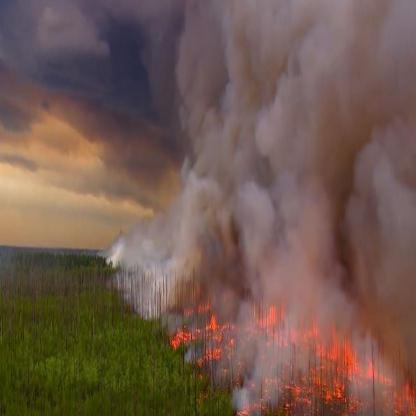

CLAHE Image: /content/fire-smoke/train/images/MirrorWEBFire001_jpg.rf.4b3b1d19e9361499087e40494bf31512.jpg


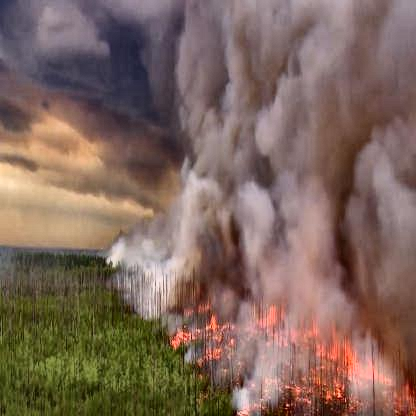

Streaming output truncated to the last 5000 lines.
/content/fire-smoke_clahe/train/images/WEBSmoke285_jpg.rf.0319a858a04bc15d9aa08bd0ff49a88c.jpg Success!
/content/fire-smoke_clahe/train/images/WEBSmoke2862_jpg.rf.84b1a27d39c79200d130cd39b1e54de1.jpg Success!
/content/fire-smoke_clahe/train/images/WEBSmoke2863_jpg.rf.49232c528c3c7c481c9f12871b591dc4.jpg Success!
/content/fire-smoke_clahe/train/images/WEBSmoke2864_jpg.rf.254ffa7309571cc19725be860ad5440f.jpg Success!
/content/fire-smoke_clahe/train/images/WEBSmoke2866_jpg.rf.e8f0bd6173289235c8204f32d7e5438c.jpg Success!
/content/fire-smoke_clahe/train/images/WEBSmoke2869_jpg.rf.b82ed6a844ce4b25a543d53d042b955d.jpg Success!
/content/fire-smoke_clahe/train/images/WEBSmoke2870_jpg.rf.0fd146668a1b262952377ad5cbc3a82b.jpg Success!
/content/fire-smoke_clahe/train/images/WEBSmoke2871_jpg.rf.f91a9dde8c6705f03abdacd1db25bbea.jpg Success!
/content/fire-smoke_clahe/train/images/WEBSmoke2876_jpg.rf.e07de394a22056bfa38432107e47b550.jpg Success!
/cont

'/content/drive/MyDrive/PROJECT_Fire-Smoke/datasets/fire-smoke_clahe.zip'

In [ ]:
# first_demo = True
# dataset_name = 'fire-smoke_clahe'

# for keytype, path in images_paths.items():

#     print(f'\nSet: {keytype} -- {path}')
#     os.makedirs(os.path.join(HOME, dataset_name, keytype, 'images'), exist_ok=True)
#     os.makedirs(os.path.join(HOME, dataset_name, keytype, 'labels'), exist_ok=True)

#     # copy original labels folder to new folder
#     shutil.copytree(os.path.join(HOME, 'fire-smoke', keytype, 'labels'), os.path.join(HOME, dataset_name, keytype, 'labels'), dirs_exist_ok=True)

#     for img_name in sorted(os.listdir(path)):

#         img_path = os.path.join(path, img_name)
#         if os.path.isfile(img_path) and img_name.lower().endswith(('.jpg', '.jpeg', '.png')):
#             img = cv2.imread(img_path)[..., ::-1]
#             ori = img.copy()
#             # res_he = set_he(img)
#             res_clahe = set_clahe(img)
#             # res_dgc = dual_gamma_correction(res_clahe, delta=50)
#             # res_cs = set_cs(res_dgc)

#             if first_demo:
#                 print(f'\nOriginal Image: {img_path}')
#                 display(Image.fromarray(ori))
#                 # print(f'HE Image: {img_path}')
#                 # display(Image.fromarray(res_he))
#                 print(f'CLAHE Image: {img_path}')
#                 display(Image.fromarray(res_clahe))
#                 # print(f'DGC Image: {img_path}')
#                 # display(Image.fromarray(res_dgc))
#                 # print(f'CS Image: {img_path}')
#                 # display(Image.fromarray(res_cs))
#                 first_demo = False

#             new_path = os.path.join(HOME, dataset_name, f'{keytype}/images/{img_name}')
#             try:
#                 cv2.imwrite(new_path, res_clahe)
#                 print(f'{new_path} Success!')
#             except Exception as e:
#                 print(f'Error: {e}, at {new_path}')


# # zip the dataset to gdrive
# shutil.make_archive(os.path.join(dataset_basepath, dataset_name), 'zip', os.path.join(HOME, dataset_name))


# Load Dataset and Create data.yaml

In [3]:
# 'fire-smoke', 'fire-smoke_he', 'fire-smoke_cs', 'fire-smoke_clahe-cs',
# 'fire-smoke_clahe-dgc-cs',
dataset_name = 'fire-smoke_clahe-cs'

# unzip the dataset
zip_file = os.path.join(dataset_basepath, f'{dataset_name}.zip')
!unzip -o "{zip_file}" -d "{HOME}/{dataset_name}"

# create data.yaml
data = {
    "train": os.path.join(HOME, f'{dataset_name}/train/images'),
    "val": os.path.join(HOME, f'{dataset_name}/valid/images'),
    "test": os.path.join(HOME, f'{dataset_name}/test/images'),
    "nc": 2,
    "names": ["Smoke", "Fire"]
}

path = os.path.join(HOME, dataset_name)
file_name = "data.yaml"
with open(os.path.join(path, file_name), "w") as file:
    yaml.dump(data, file, default_flow_style=False)

print(f"File YAML created successfully: {os.path.join(path, file_name)}")


Streaming output truncated to the last 5000 lines.
  inflating: /content/fire-smoke_clahe-cs/valid/labels/WEBFire142_jpg.rf.cceea8ef42942fcaa1fad56f0e75f5ac.txt  
  inflating: /content/fire-smoke_clahe-cs/valid/labels/MirrorWEBFire1590_jpg.rf.cb51b1ba579b403d2b1543c61debacb0.txt  
  inflating: /content/fire-smoke_clahe-cs/valid/labels/WEBSmoke1702_jpg.rf.e7359f70fa1cdae63dc344cae6dd182c.txt  
  inflating: /content/fire-smoke_clahe-cs/valid/labels/NoiseWEBFire1708_jpg.rf.0ad08788e19211cfe0b7d91352feda58.txt  
  inflating: /content/fire-smoke_clahe-cs/valid/labels/NoiseWEBFire1001_jpg.rf.3da1ab0d16e7ed6f08c27ad4f65ae880.txt  
  inflating: /content/fire-smoke_clahe-cs/valid/labels/MirrorWEBSmoke2808_jpg.rf.26c01e7813277b297f8dab0cba59efd5.txt  
  inflating: /content/fire-smoke_clahe-cs/valid/labels/NoiseWEBFire285_jpg.rf.51a41425bbbc39472a79d66f5e98c704.txt  
  inflating: /content/fire-smoke_clahe-cs/valid/labels/WEBSmoke813_jpg.rf.5f2c514a2a1d0fd80f585d1ced73e5d0.txt  
  inflating: /cont

# Setup YOLO Model

In [4]:
model_path = os.path.join(project_basepath, 'ultralytics/ultralytics/cfg/models')

# Parameters
pretrained_weight = 'yolo11s.pt'
evcattn_cfg = os.path.join(model_path, '11', 'yolo11s-ghost_bifpn_ca_evcattn.yaml')
epochs = 300
batch_size = 128
imgsz = 640
optimz = 'SGD'
warmup_epochs = 3.0
in_lr_rate = 1e-2
wDecay = 5e-4
augment = False
momentum = 0.937
iou = 0.5

data_path = f'{HOME}/{dataset_name}/data.yaml'
project_name = os.path.join(project_basepath, 'runs/yolo11-ghost_neck_extend_runs')
device_type = 0 if torch.cuda.is_available() else 'cpu'


## Training

In [ ]:
model = YOLO(pretrained_weight)

results_train = model.train(
    data=data_path,
    epochs=epochs,
    batch=batch_size,
    imgsz=imgsz,
    optimizer=optimz,
    warmup_epochs=warmup_epochs,
    momentum=momentum,
    lr0=in_lr_rate,
    weight_decay=wDecay,
    augment=augment,
    project=project_name,
    name=pretrained_weight.replace('.pt', '') + '_train',
    device=device_type,
)

100%|██████████| 21.5M/21.5M [00:00<00:00, 157MB/s] 


Ultralytics 8.3.65 🚀 Python-3.11.11 torch-2.5.1+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40514MiB)
engine/trainer: task=detect, mode=train, model=yolov8s.pt, data=/content/fire-smoke_clahe/data.yaml, epochs=300, time=None, patience=100, batch=128, imgsz=640, save=True, save_period=-1, cache=False, device=0, workers=8, project=/content/drive/MyDrive/PROJECT_Fire-Smoke/runs/yolov8_clahe_runs, name=yolov8s_train, exist_ok=False, pretrained=True, optimizer=SGD, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_nms=False, classes=None, retina_masks=False, embed=None, show=False, save_frames=False, save_t

100%|██████████| 755k/755k [00:00<00:00, 14.7MB/s]


Overriding model.yaml nc=80 with nc=2

                   from  n    params  module                                       arguments                     
  0                  -1  1       928  ultralytics.nn.modules.conv.Conv             [3, 32, 3, 2]                 
  1                  -1  1     18560  ultralytics.nn.modules.conv.Conv             [32, 64, 3, 2]                
  2                  -1  1     29056  ultralytics.nn.modules.block.C2f             [64, 64, 1, True]             
  3                  -1  1     73984  ultralytics.nn.modules.conv.Conv             [64, 128, 3, 2]               
  4                  -1  2    197632  ultralytics.nn.modules.block.C2f             [128, 128, 2, True]           
  5                  -1  1    295424  ultralytics.nn.modules.conv.Conv             [128, 256, 3, 2]              
  6                  -1  2    788480  ultralytics.nn.modules.block.C2f             [256, 256, 2, True]           
  7                  -1  1   1180672  ultralytics

100%|██████████| 5.35M/5.35M [00:00<00:00, 67.2MB/s]


...

    300/300        28G     0.4806     0.2659     0.8869        115        640: 100%|██████████| 67/67 [00:31<00:00,  2.14it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 9/9 [00:07<00:00,  1.17it/s]

                   all       2114       6319      0.894      0.833      0.886      0.662



300 epochs completed in 3.350 hours.
Optimizer stripped from /content/drive/MyDrive/PROJECT_Fire-Smoke/runs/yolov8_clahe_runs/yolov8s_train/weights/last.pt, 22.6MB
Optimizer stripped from /content/drive/MyDrive/PROJECT_Fire-Smoke/runs/yolov8_clahe_runs/yolov8s_train/weights/best.pt, 22.6MB

Validating /content/drive/MyDrive/PROJECT_Fire-Smoke/runs/yolov8_clahe_runs/yolov8s_train/weights/best.pt...
Ultralytics 8.3.65 🚀 Python-3.11.11 torch-2.5.1+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40514MiB)
Model summary (fused): 168 layers, 11,126,358 parameters, 0 gradients, 28.4 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 9/9 [00:11<00:00,  1.23s/it]


                   all       2114       6319      0.894      0.833      0.886      0.662
                 Smoke       1902       2250       0.91      0.867      0.911       0.72
                  Fire       1360       4069      0.878      0.799      0.861      0.603
Speed: 0.2ms preprocess, 0.7ms inference, 0.0ms loss, 1.3ms postprocess per image
Results saved to /content/drive/MyDrive/PROJECT_Fire-Smoke/runs/yolov8_clahe_runs/yolov8s_train


In [ ]:
results_train

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7a1bb414c190>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04804

## Eval

In [ ]:
model = YOLO(os.path.join(project_name, 'yolo11s_train/weights/best.pt'))

results_val = model.val(
    data=data_path,
    batch=batch_size,
    imgsz=imgsz,
    iou=iou,
    augment=augment,
    project=project_name,
    name=pretrained_weight.replace('.pt', '') + '_val',
    device=device_type,
)

Ultralytics 8.3.79 🚀 Python-3.11.11 torch-2.5.1+cu124 CUDA:0 (NVIDIA A100-SXM4-40GB, 40507MiB)
YOLO11s summary (fused): 100 layers, 9,413,574 parameters, 0 gradients, 21.3 GFLOPs


100%|██████████| 755k/755k [00:00<00:00, 102MB/s]
val: Scanning /content/fire-smoke_clahe-cs/valid/labels... 2114 images, 0 backgrounds, 0 corrupt: 100%|██████████| 2114/2114 [00:01<00:00, 1343.20it/s]


val: New cache created: /content/fire-smoke_clahe-cs/valid/labels.cache


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 17/17 [00:14<00:00,  1.19it/s]


                   all       2114       6319      0.901      0.842      0.899      0.671
                 Smoke       1902       2250       0.93      0.878      0.929      0.734
                  Fire       1360       4069      0.873      0.806      0.869      0.607
Speed: 0.8ms preprocess, 1.2ms inference, 0.0ms loss, 0.9ms postprocess per image
Results saved to /content/drive/MyDrive/PROJECT_Fire-Smoke/runs/yolo11_clahe-cs_runs/yolo11s_val3


In [ ]:
results_val

## Testing

In [ ]:
model = YOLO(os.path.join(project_name, 'yolo11s_train/weights/best.pt'))

results_predict = model.predict(
    source=f'{HOME}/{dataset_name}/test/images/',
    imgsz=imgsz,
    iou=iou,
    device=device_type,
)



WARNING ⚠️ inference results will accumulate in RAM unless `stream=True` is passed, causing potential out-of-memory
errors for large sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict/ for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

image 1/1059 /content/fire-smoke/test/images/MirrorWEBFire004_jpg.rf.f22cdb22d15cbc7b27b3c3656dbb30cf.jpg: 640x640 1 Smoke, 3 Fires, 15.4ms
image 2/1059 /content/fire-smoke/test/images/MirrorWEBFire012_jpg.rf.c5f033de58daf52390659dbabf0f1cb4.jpg: 640x640 1 Smoke, 1 Fire, 11.0ms
image 3/1059 /content/fire-smoke/test/images/MirrorWEBFire041_jpg.rf.0f5a5688e0bd986267f45341b5c64655.jpg: 640x640 2 Smokes, 1 Fire, 9.8ms
image 4/1059 /content/fire-smoke/test/

In [ ]:
from PIL import Image
import cv2

for img in results_predict[40:60]:
    image = img.plot()
    image = Image.fromarray(image[..., ::-1])
    display(image)
    # break

Output hidden; open in https://colab.research.google.com to view.

# EVCAttn

In [5]:
import os
import sys
ultralytics_path = os.path.join(project_basepath, 'ultralytics')
if not ultralytics_path in sys.path:
  sys.path.append(os.path.abspath(ultralytics_path))

try:
    from ultralytics import YOLO as YOLO_EVCAttn
except:
    !pip install -q timm==0.4.12 efficientnet-pytorch==0.7.1
    from ultralytics import YOLO as YOLO_EVCAttn


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


/usr/local/lib/python3.11/dist-packages/timm/models/layers/__init__.py:48: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 377.0/377.0 kB 10.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 96.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 78.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 43.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 36.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 9.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 80.8 MB/s eta 0:00:00


In [6]:
import yaml

cfg_name = 'yolo11-evcattn_exp.yaml'

# Create YOLO cfg
data = {
    # Parameters
    "nc": 2,  # number of classes
    "scales": { # model compound scaling constants, i.e. 'model=yolo11n.yaml' will call yolo11.yaml with scale 'n'
        # [depth, width, max_channels]
        "n": [0.50, 0.25, 1024],
        "s": [0.50, 0.50, 1024],
        "m": [0.50, 1.00, 512],
        "l": [1.00, 1.00, 512],
        "x": [1.00, 1.50, 512],
    },

    # Default
    # "backbone": [
    #     # [from, repeats, module, args]
    #     [-1, 1, "Conv", [64, 3, 2]], # 0-P1/2
    #     [-1, 1, "Conv", [128, 3, 2]], # 1-P2/4

    #     [-1, 2, "C3k2", [256, False, 0.25]],
    #     [-1, 1, "Conv", [256, 3, 2]], # 3-P3/8

    #     [-1, 2, "C3k2", [512, False, 0.25]],

    #     [-1, 1, "Conv", [512, 3, 2]], # 5-P4/16
    #     [-1, 2, "C3k2", [512, True]],

    #     [-1, 1, "Conv", [1024, 3, 2]], # 7-P5/32
    #     [-1, 2, "C3k2", [1024, True]],

    #     [-1, 1, "SPPF", [1024, 5]], # 9
    #     [-1, 2, "C2PSA", [1024]], # 10
    # ],
    # "head": [
    #     [-1, 1, "nn.Upsample", [None, 2, "nearest"]],
    #     [[-1, 6], 1, "Concat", [1]], # cat backbone P4
    #     [-1, 2, "C3k2", [512, False]], # 13

    #     [-1, 1, "nn.Upsample", [None, 2, "nearest"]],
    #     [[-1, 4], 1, "Concat", [1]], # cat backbone P3
    #     [-1, 2, "C3k2", [256, False]], # 16 (P3/8-small)

    #     [-1, 1, "Conv", [256, 3, 2]],
    #     [[-1, 13], 1, "Concat", [1]], # cat head P4
    #     [-1, 2, "C3k2", [512, False]], # 19 (P4/16-medium)

    #     [-1, 1, "Conv", [512, 3, 2]],
    #     [[-1, 10], 1, "Concat", [1]], # cat head P5
    #     [-1, 2, "C3k2", [1024, True]], # 22 (P5/32-large)

    #     [[16, 19, 22], 1, "Detect", ["nc"]], # Detect(P3, P4, P5)
    # ],

    # Custom
    "backbone": [
        # [from, repeats, module, args]
        [-1, 1, "Conv", [64, 3, 2]], # 0-P1/2

        [-1, 1, "Conv", [128, 3, 2]], # 1-P2/4
        [-1, 2, "C3k2", [256, False, 0.25]],

        [-1, 1, "Conv", [256, 3, 2]], # 3-P3/8
        [-1, 2, "C3k2", [512, False, 0.25]],

        [-1, 1, "Conv", [512, 3, 2]], # 5-P4/16
        [-1, 2, "C3k2", [512, True]],

        [-1, 1, "Conv", [1024, 3, 2]], # 7-P5/32
        [-1, 2, "C3k2", [1024, True]],

        [-1, 1, "SPPF", [1024, 5]], # 9
        [-1, 2, "C2PSA", [1024]], # 10
    ],
    "head": [
        [-1, 1, "nn.Upsample", [None, 2, "nearest"]],
        [[-1, 6], 1, "Concat", [1]], # cat backbone P4
        [-1, 2, "C3k2", [512, False]], # 13

        [-1, 1, "nn.Upsample", [None, 2, "nearest"]],
        [[-1, 4], 1, "Concat", [1]], # cat backbone P3
        [-1, 2, "C3k2", [256, False]], # 16 (P3/8-small)

        [-1, 1, "nn.Upsample", [None, 2, 'nearest']],
        [[-1, 2], 1, "Concat", [1]], # cat backbone P2
        [-1, 2, "C3k2", [128, False]], # 19 (P2/4-xsmall)

        [-1, 1, "GhostConv", [128, 3, 2]],
        [[-1, 16], 1, "Concat", [1]], # cat head P3
        [-1, 2, "C3k2Ghost4", [256, False]], # 22 (P3/8-small)

        [-1, 1, "GhostConv", [256, 3, 2]],
        [[-1, 13], 1, "Concat", [1]], # cat head P4
        [-1, 2, "C3k2Ghost4", [512, False]], # 25 (P4/16-medium)

        [-1, 1, "GhostConv", [512, 3, 2]],
        [[-1, 10], 1, "Concat", [1]], # cat head P5
        [-1, 2, "C3k2Ghost4", [1024, True]], # 28 (P5/32-large)

        [[19, 22, 25, 28], 1, "Detect", ["nc"]] # Detect(P2, P3, P4, P5)
    ],
}

with open(os.path.join(HOME, cfg_name), "w") as file:
    yaml.dump(data, file, default_flow_style=False, sort_keys=False)

print(f"File YAML created successfully: {os.path.join(HOME, cfg_name)}")

File YAML created successfully: /content/yolo11-evcattn_exp.yaml


In [ ]:
cfg = os.path.join(HOME, 'yolo11s-evcattn_exp.yaml')
model_evcattn = YOLO_EVCAttn(cfg).load(pretrained_weight)

results_train = model_evcattn.train(
    data=data_path,
    epochs=epochs,
    batch=64, # 32
    imgsz=imgsz,
    optimizer=optimz,
    warmup_epochs=warmup_epochs,
    momentum=momentum,
    lr0=in_lr_rate,
    weight_decay=wDecay,
    augment=augment,
    project=project_name,
    name=pretrained_weight.replace('.pt', '') + '_train',
    device=device_type,
)

Transferred 294/659 items from pretrained weights
New https://pypi.org/project/ultralytics/8.3.79 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.58 🚀 Python-3.11.11 torch-2.5.1+cu124 CUDA:0 (NVIDIA A100-SXM4-40GB, 40507MiB)
engine/trainer: task=detect, mode=train, model=/content/yolo11s-evcattn_exp.yaml, data=/content/fire-smoke_clahe-cs/data.yaml, epochs=300, time=None, patience=100, batch=64, imgsz=640, save=True, save_period=-1, cache=False, device=0, workers=8, project=/content/drive/MyDrive/PROJECT_Fire-Smoke/runs/yolo11-ghost_neck_extend_runs, name=yolo11s_train2, exist_ok=False, pretrained=yolo11s.pt, optimizer=SGD, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, 

train: Scanning /content/fire-smoke_clahe-cs/train/labels... 8494 images, 3 backgrounds, 0 corrupt: 100%|██████████| 8494/8494 [00:05<00:00, 1448.60it/s]


train: New cache created: /content/fire-smoke_clahe-cs/train/labels.cache
albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, num_output_channels=3, method='weighted_average'), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8))


/content/drive/MyDrive/PROJECT_Fire-Smoke/ultralytics/ultralytics/data/augment.py:1853: UserWarning: Argument(s) 'quality_lower' are not valid for transform ImageCompression
  A.ImageCompression(quality_lower=75, p=0.0),
val: Scanning /content/fire-smoke_clahe-cs/valid/labels... 2114 images, 0 backgrounds, 0 corrupt: 100%|██████████| 2114/2114 [00:01<00:00, 1371.52it/s]

val: New cache created: /content/fire-smoke_clahe-cs/valid/labels.cache


...

    300/300      26.3G     0.4997     0.2643     0.9543        118        640: 100%|██████████| 133/133 [00:56<00:00,  2.35it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 17/17 [00:09<00:00,  1.80it/s]

                   all       2114       6319      0.906       0.83      0.896      0.674



300 epochs completed in 5.639 hours.
Optimizer stripped from /content/drive/MyDrive/PROJECT_Fire-Smoke/runs/yolo11-ghost_neck_extend_runs/yolo11s_train2/weights/last.pt, 17.5MB
Optimizer stripped from /content/drive/MyDrive/PROJECT_Fire-Smoke/runs/yolo11-ghost_neck_extend_runs/yolo11s_train2/weights/best.pt, 17.5MB

Validating /content/drive/MyDrive/PROJECT_Fire-Smoke/runs/yolo11-ghost_neck_extend_runs/yolo11s_train2/weights/best.pt...
Ultralytics 8.3.58 🚀 Python-3.11.11 torch-2.5.1+cu124 CUDA:0 (NVIDIA A100-SXM4-40GB, 40507MiB)
YOLO11s-evcattn_exp summary (fused): 336 layers, 8,438,920 parameters, 0 gradients


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 17/17 [00:11<00:00,  1.48it/s]


                   all       2114       6319      0.906      0.831      0.896      0.674
                 Smoke       1902       2250      0.931      0.864      0.924      0.733
                  Fire       1360       4069      0.881      0.798      0.868      0.614
Speed: 0.1ms preprocess, 1.2ms inference, 0.0ms loss, 1.0ms postprocess per image
Results saved to /content/drive/MyDrive/PROJECT_Fire-Smoke/runs/yolo11-ghost_neck_extend_runs/yolo11s_train2


In [ ]:
results_train

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7d39b05a0d50>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04804

In [8]:
model = YOLO_EVCAttn(os.path.join(project_name, 'yolo11s_train/weights/best.pt'))

results_val = model.val(
    data=data_path,
    batch=8, # 32
    imgsz=imgsz,
    iou=iou,
    augment=augment,
    project=project_name,
    name=pretrained_weight.replace('.pt', '') + '_val',
    device=device_type,
)

Ultralytics 8.3.58 🚀 Python-3.11.11 torch-2.5.1+cu124 CPU (Intel Xeon 2.20GHz)
YOLO11s-evcattn_exp summary (fused): 336 layers, 8,438,920 parameters, 0 gradients


val: Scanning /content/fire-smoke_clahe-cs/valid/labels.cache... 2114 images, 0 backgrounds, 0 corrupt: 100%|██████████| 2114/2114 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 1057/1057 [09:45<00:00,  1.80it/s]


                   all       2114       6319       0.89      0.851        0.9       0.68
                 Smoke       1902       2250      0.923       0.88      0.926      0.737
                  Fire       1360       4069      0.858      0.822      0.875      0.623
Speed: 0.6ms preprocess, 262.8ms inference, 0.0ms loss, 4.8ms postprocess per image
Results saved to /content/drive/MyDrive/PROJECT_Fire-Smoke/runs/yolo11-ghost_neck_extend_runs/yolo11s_val


In [ ]:
results_val